# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola Maria! ¿Cómo va?<br><br>
Un gusto conocerte, soy Santiago y seré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones por el esfuerzo! Tu código está muy bien resuelto: varias de tus soluciones (la mediana sin el sentinel, la <i>named aggregation</i>, <code>np.select</code> o los boxplots con <code>subplot</code>) son incluso más elegantes de lo que se pide. Donde más espacio de mejora hay es en <b>contar lo que encuentras</b>: las interpretaciones y el resumen ejecutivo. Recuerda que equivocarse es parte del aprendizaje: cada iteración te acerca a pensar como un gran analista de datos.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración completas (ojo con un detalle en <code>shape</code>).</li>
<li><b>Parte 2. Calidad de datos ❌</b> — Código correcto: <code>value_counts(dropna=False)</code>, <code>errors='coerce'</code> y conteo por año. Pero <b>cuatro interpretaciones del paso 2.2 quedaron sin contestar</b>, y el diagnóstico no menciona los sentinels <code>-999</code> y <code>"?"</code> ni el año 2026.</li>
<li><b>Parte 3. Limpieza ✅</b> — ¡Muy bien! Mediana calculada sin el sentinel, <code>"?"</code> a nulo, fechas de 2026 marcadas con <code>.mask()</code> y decisión MAR correcta.</li>
<li><b>Parte 4. Uso por usuario ✅</b> — <i>Named aggregation</i> y <code>merge</code> con <code>how='left'</code> correctos.</li>
<li><b>Parte 5. Distribuciones y outliers 🟡</b> — Gráficos y cálculo IQR correctos; algunos insights afirman diferencias entre planes que los datos no respaldan.</li>
<li><b>Parte 6. Segmentación ✅</b> — <code>np.select</code> bien aplicado y countplots bien rotulados.</li>
<li><b>Parte 7. Insight ejecutivo ❌</b> — El resumen no incluye cifras, no describe el comportamiento de los segmentos ni identifica los más valiosos.</li>
<li><b>Parte 8. Publicación 🟡</b> — El link está en una celda de código y apunta a un repositorio con otro nombre.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto <b>aún no puede ser aceptado</b> porque hay preguntas sin contestar:
<ol><li>Las cuatro celdas de interpretación del paso 2.2 (columnas numéricas de <code>users</code> y <code>usage</code>, categóricas de <code>users</code> y <code>type</code>).</li>
<li>El <b>análisis ejecutivo</b> (paso 7), donde todo tu trabajo técnico se convierte en conclusiones para el negocio.</li></ol>
Tu código ya tiene las respuestas; solo falta escribirlas. Los comentarios amarillos son recomendaciones para fortalecer tu trabajo.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [11]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Importaste todas las librerías, incluido <code>numpy</code>, en una sola celda al inicio. ¡Buena práctica!
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Como <code>numpy</code> ya está importado aquí, puedes quitar los <code>import numpy as np</code> repetidos de las celdas del paso 6.
</div>

In [12]:

# cargar archivos
plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")#completa el código
usage = pd.read_csv("/datasets/usage.csv")#completa el código


In [18]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [19]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [20]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
En Jupyter, si la tabla es la última línea de la celda se muestra sola; no hace falta <code>display()</code>. Es útil cuando quieres mostrar varias tablas en una misma celda.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [16]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa la última línea: imprime <code>users.shape</code> con la etiqueta "usage", por eso muestra (4000, 8) en lugar de (40 000, 6). Es un detalle pequeño, pero una cifra equivocada al inicio puede llevar a conclusiones erradas.
</div>

In [17]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [19]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [20]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Inspección con <code>.info()</code> completa en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [21]:
# cantidad de nulos para users
print("---nulos en users---")# Cantidad de valores nulos
display(users.isna().sum())
print("\n--- Proporcion de nulos en users ---")# Proporción de valores nulos
display(users.isna().mean())
    
    

---nulos en users---


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


--- Proporcion de nulos en users ---


user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

In [22]:
# cantidad de nulos para usage
print("\n---nulos en usage---")
display(usage.isna().sum())
print("\n---proporcion de nulos en usage---")
display(usage.isna().mean())



---nulos en usage---


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


---proporcion de nulos en usage---


id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo y proporción de nulos correctos en ambos datasets, con encabezados que facilitan la lectura.
</div>


**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  la columna de city tiene un 11.72%, churn_date un 88.35%, date con un 0.125%, duration con un 55.19% y length con un 44.74%
- Indica qué harías: ¿imputar, eliminar, ignorar? en el caso de date, city, y length se dejarian como nulos o desconocidos, para  churn_date se ignora o elimina debido a tener mas del 80% y en el caso de duration se recomienda ignorar los datos faltantes tambien

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisemos el diagnóstico:
<ul>
<li><code>date</code> tiene 0.00125 de nulos, es decir, <b>0.125 %</b> (50 filas), no 12.5 %.</li>
<li>Falta <code>duration</code> (55.2 %).</li>
<li>No conviene imputar <code>date</code> (no se puede inventar una fecha) ni <code>length</code>: en el paso 3.2 verás que esos nulos tienen una razón de ser. Para <code>city</code>, puedes dejarlos como nulos o usar una categoría "Desconocida".</li>
<li>Muy bien ignorar <code>churn_date</code>: el nulo significa que el cliente sigue activo.</li>
<li>Borra el texto de la plantilla y deja solo tu diagnóstico.</li>
</ul>
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [21]:
# explorar columnas numéricas de users
print("---Describe users---")
display(users.describe())

---Describe users---


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


... Haz doble clic en este bloque y escribe qué ves.
- La columna `user_id` - La columna `user_id` nos presenta una distribucion uniforme de 4000 registros que van desde 10000 a 13999 con una media y mediana iguales lo que nos confirma que tenemos una secuencia limpia
- La columna `age` para la columna age tambien tenemos un conteo de 4000, sin embargo tenemos una minima imposible de -999 lo cual hace que los resultados de standard se inflen a 123.23 y hacen que la media sea mas baja a un 33.7 en lugar de la media real que es de 47.

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Esta celda quedó sin contestar (conserva el texto de la plantilla). El código que ejecutaste es correcto, así que solo falta escribir lo que ves. Pistas: ¿qué te dice el mínimo de <code>-999</code> en <code>age</code>? ¿Es una edad posible? ¿Cómo afecta a la media (33.7) frente a la mediana (47)?
</div>

In [24]:
# explorar columnas numéricas de usage
print("---Describe usage---")
display(usage.describe())

---Describe usage---


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


 ...Haz doble clic en este bloque y escribe qué ves.
- Las columnas `id` y `user_id` nos muestran los resultados de un conteo de 4000, aunque para la columna de ID la media y la mediana sean iguales notamos valores faltantes en length y duration asi como maximos muy elevados de 120 y 1490

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Esta celda quedó sin contestar. Describe lo que muestra tu <code>describe()</code>: ¿hay valores inválidos en los identificadores? Pista: en <code>duration</code> y <code>length</code> hay mínimos de 0 (sospechosos) y máximos muy alejados del percentil 75 (120 y 1490) que pueden ser outliers.
</div>

In [26]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- Valores únicos y frecuencias para: {col} ---")
    display(users[col].value_counts(dropna=False))
    print("\n")


--- Valores únicos y frecuencias para: city ---


Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64



--- Valores únicos y frecuencias para: plan ---


Basico     2595
Premium    1405
Name: plan, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien usar <code>value_counts(dropna=False)</code> en un ciclo! La salida muestra a la vez los 469 nulos y los 96 registros con <code>"?"</code>.
</div>

- La columna `city` presenta problemas de datos faltantes con una cantidad de 469, asi como 96 datos que tienen un caracter de ? que nos indica que tambien son datos faltantes o invalidos 
- La columna `plan` nos muestra que solo se ofrecen dos tipos de planes siendo estos el basico y el premium

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Esta celda quedó sin contestar. Describe lo que muestra tu salida, que ya tiene toda la información: 6 ciudades válidas, 469 nulos y el sentinel <code>"?"</code> (96 registros); en <code>plan</code>, solo Básico y Premium.
</div>

In [5]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False) # completa el código


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` no nos muestra ningun tipo de dato faltante y nos muestra los datos de mensaje de texto y llamadas totales.

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Esta celda quedó sin contestar. Describe lo que muestra tu salida: ¿cuántas categorías tiene <code>type</code>, cuáles son y hay valores inválidos o mal escritos?
</div>

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  Se encontraron datos invalidos en age ademas de valores sospechosos en duration y length
- ¿Qué acción tomarías?  se recomendaria analisar si los datos faltantes se podrian mantener como nulos o cambiarlos a un dato como desconocido

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa el diagnóstico: los datos que <b>faltan</b> en <code>city</code> (los 469 nulos) no son sentinels. Un sentinel es un valor que <i>está</i> en los datos pero representa algo inválido o desconocido. Tus propias salidas muestran dos:
<ul><li><code>-999</code> en <code>age</code> (55 filas), una edad imposible.</li>
<li><code>"?"</code> en <code>city</code> (96 filas), que <code>isna()</code> no detecta.</li></ul>
Indica ambos con su acción (los corriges muy bien en el paso 3.1).
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [8]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código


In [9]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce') # completa el código

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> en ambas columnas. ¡Bien!
</div>

In [10]:
print(users['reg_date'].dt.year.value_counts(dropna=False))# Revisar los años presentes en `reg_date` de users


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo por año con <code>.dt.year.value_counts(dropna=False)</code>, tal como se pedía.
</div>

En `reg_date`, se incluyen los datos del año 2022 con 1314, el 2023 con 1316, 2024 con 1314 y el año 2026 con 40 registros siendo este ultimo un dato imposible

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien que indicas el rango de años. Completa la interpretación con las cantidades de cada año y borra el texto de la plantilla. Fíjate especialmente en los 40 registros de 2026.
</div>

In [11]:
print(usage['date'].dt.year.value_counts(dropna=False))# Revisar los años presentes en `date` de usage


2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, se encuentran los datos solamente del año 2024 y tambien se incluyen 50 datos nulos
Basaremos el análisis en estas fechas.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcto: en <code>date</code> solo aparece 2024, más 50 nulos.
</div>

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? en el caso de reg_date se incluyen los datos desde el año 2022 hasta el año 2026, siendo el 2026 datos imposibles
- ¿Qué harías con ellas? se recomendaria ignorar los datos imposibles del año 2026

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa la lectura: 2022 y 2023 no son años imposibles; son registros de clientes que se unieron antes y son válidos (los datos llegan <b>hasta</b> 2024). El año imposible es <b>2026</b>, una fecha futura con 40 registros. Ignorar los anteriores a 2024 haría perder dos tercios de los clientes. Tu limpieza del paso 3.1 sí marca correctamente solo los de 2026, así que ajusta aquí el diagnóstico para que coincida.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [12]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].replace(-999, np.nan).median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente! Calculaste la mediana <b>excluyendo</b> el sentinel (convirtiéndolo antes a <code>NaN</code>), así el <code>-999</code> no participa en el cálculo. La validación lo confirma: mínimo 18 y mediana 48.
</div>

In [14]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo correcto de <code>"?"</code> por <code>pd.NA</code>, verificado con <code>value_counts(dropna=False)</code>: los nulos pasan de 469 a 565.
</div>

In [19]:
# # Marcar fechas futuras como NA para reg_date

users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
users['reg_date'] = users['reg_date'].mask(users['reg_date'].dt.year > 2024, pd.NA)

# Verificar cambios
print(pd.to_datetime(users['reg_date']).dt.year.value_counts(dropna=False))



2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy elegante el uso de <code>.mask()</code> con <code>&gt; 2024</code>! Solo se marcan como nulas las 40 fechas de 2026 y la verificación lo confirma.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>reg_date</code> ya está convertida desde el paso 2.3, así que no hace falta volver a aplicar <code>pd.to_datetime</code> ni en la limpieza ni en la verificación.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [18]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')[['duration', 'length']].agg(lambda x: x.isna().mean()))

      duration   length
type                   
call  0.000000  0.99933
text  0.999276  0.00000


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Calculaste la proporción de nulos de <code>duration</code> y <code>length</code> por tipo en una sola tabla.
</div>

In [20]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].agg(lambda x: x.isna().mean()))

type
call    0.99933
text    0.00000
Name: length, dtype: float64


<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Esta celda repite el cálculo de <code>length</code> que ya hiciste en la anterior. También puedes usar la forma vectorizada, sin <code>lambda</code>:<br><code>usage[['duration','length']].isna().groupby(usage['type']).mean()</code>
</div>

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`  se confirma que son nulos MAR debido a que duration y length miden rangos diferentes el primero sirve para datos de llamadas mientras el segundo se usa para mensajes, por lo tanto se recomendaria mantenerlos como nulos

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conclusión MAR correcta y decisión bien justificada: cada columna aplica a un solo tipo de evento, así que se mantienen como nulos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Borra el texto de la plantilla al inicio de la celda.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Usaste <b>named aggregation</b>: agrupaste y nombraste las columnas en un solo paso.
</div>

In [28]:
# Renombrar columnas
users_merged = pd.merge(users, usage_agg, on="user_id", how="left")
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Como la <i>named aggregation</i> ya nombra las columnas, este paso no requiere código. El <code>merge</code> de esta celda crea <code>users_merged</code>, que no se usa y repite el de la celda siguiente; puedes eliminarlo.
</div>

In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien usar <code>how='left'</code> desde <code>users</code>: así conservas a los 4000 clientes, incluido el que no registró uso.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al conservar a ese usuario sin actividad, sus métricas quedan en <code>NaN</code> (por eso el <code>describe()</code> muestra 3999). Como no tener registros significa <b>cero</b> mensajes, llamadas y minutos, conviene rellenar esas tres columnas con 0 justo después del merge. Esto también evita el problema que te comento en la segmentación por uso.
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
display(user_profile.describe())


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,33.739750,5.524381,4.478120,23.317054
std,1154.844867,123.232257,2.358416,2.144238,18.168095
min,10000.000000,-999.000000,0.000000,0.000000,0.000000
25%,10999.750000,32.000000,4.000000,3.000000,11.120000
50%,11999.500000,47.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Selecciona solo las columnas relevantes (<code>age</code>, <code>cant_mensajes</code>, <code>cant_llamadas</code>, <code>cant_minutos_llamada</code>): la media o los cuartiles de <code>user_id</code> no tienen significado. Agrega también una breve interpretación con medianas, rangos y máximos.
</div>

In [31]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)


Basico     64.875
Premium    35.125
Name: plan, dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Distribución porcentual de planes correcta: ~65 % Básico y ~35 % Premium.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

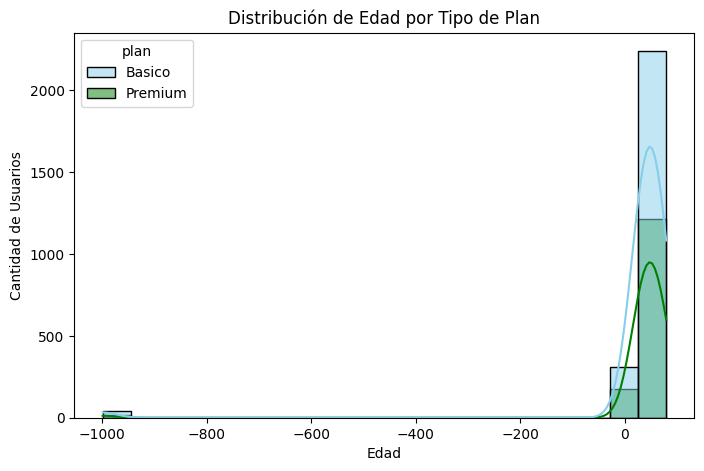

In [36]:
# Histograma para visualizar la edad (age) segmentada por plan

plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Histogramas completos: <code>hue='plan'</code>, paleta indicada, KDE, título y etiquetas en ambos ejes.
</div>

💡Insights: 
- Distribución nos muestra que hay un uso similar de los servicios para los planes basico y premium

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Antes de afirmar que Premium se usa más en edades avanzadas, ten en cuenta que en un histograma de conteos es difícil comparar los planes, porque hay casi el doble de clientes Básico. Verifícalo con proporciones, por ejemplo con <code>stat='density', common_norm=False</code> en <code>histplot</code>. Indica también la forma de la distribución (aquí es aproximadamente uniforme) y borra los <code>...</code> de la plantilla.
</div>

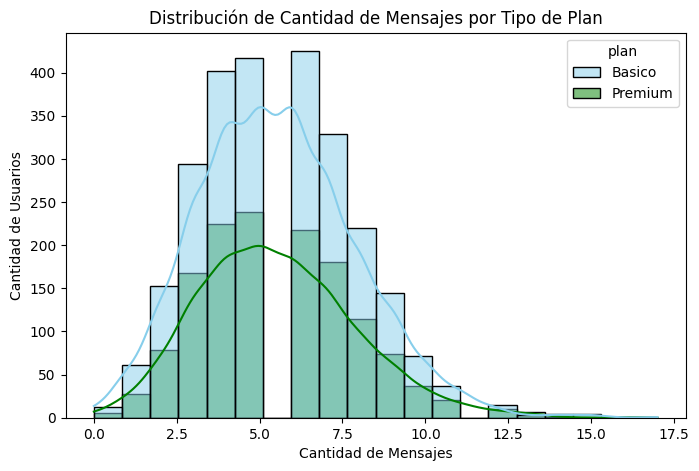

In [27]:
# Histograma para visualizar la cantidad de mensajes (cant_mensajes) segmentada por plan
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de Cantidad de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡Insights: 
- ....se encuentra que tanto los usuarios del plan basico y premium registran un uso bajo de mensajes mientras que un pequeño porcentaje de ambos planes tiene uso de mensajes bastante alto que hace que exista un sesgo a la derecha

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el sesgo a la derecha y que ambos planes se comportan de forma similar.
</div>

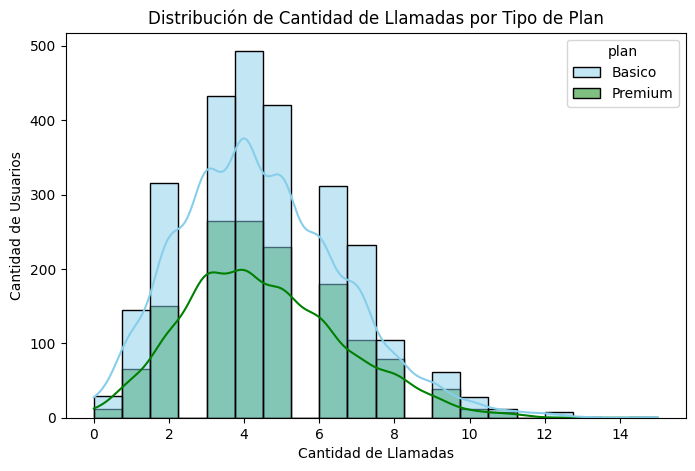

In [28]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de Cantidad de Llamadas por Tipo de Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- Distribución ... se encuentra que los usuarios de los planes basico y premium registran una cantidad de llamadas similar

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Esta conclusión no coincide con lo que muestran los datos. Las barras de Básico son más altas porque hay más clientes, y si comparas las medianas por plan (<code>user_profile.groupby('plan')['cant_llamadas'].median()</code>) verás que ambos planes hacen una cantidad similar de llamadas. Indica también la forma de la distribución.
</div>

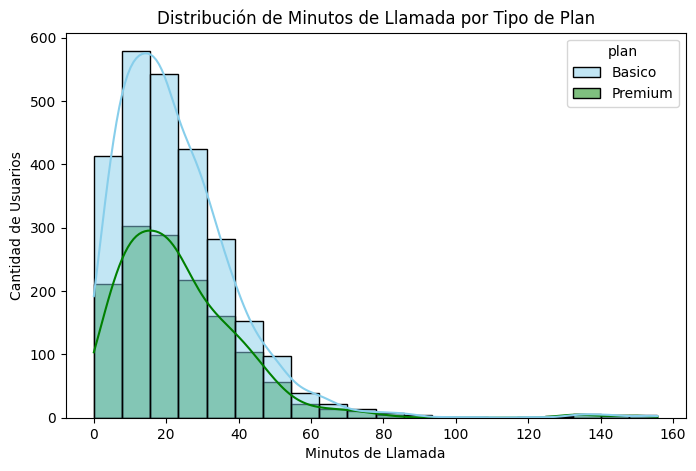

In [29]:

# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Minutos de Llamada')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 
- ... se muestra un claro sesgo a la derecha que nos indica que la mayor parte de los usuarios tienen cantidades bajas de minutos de llamada

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcto el sesgo a la derecha: la mayoría de los usuarios acumula pocos minutos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Completa el insight con la comparación entre planes, el rango típico (la mayoría acumula entre 10 y 30 minutos en total) y borra los <code>...</code> de la plantilla.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

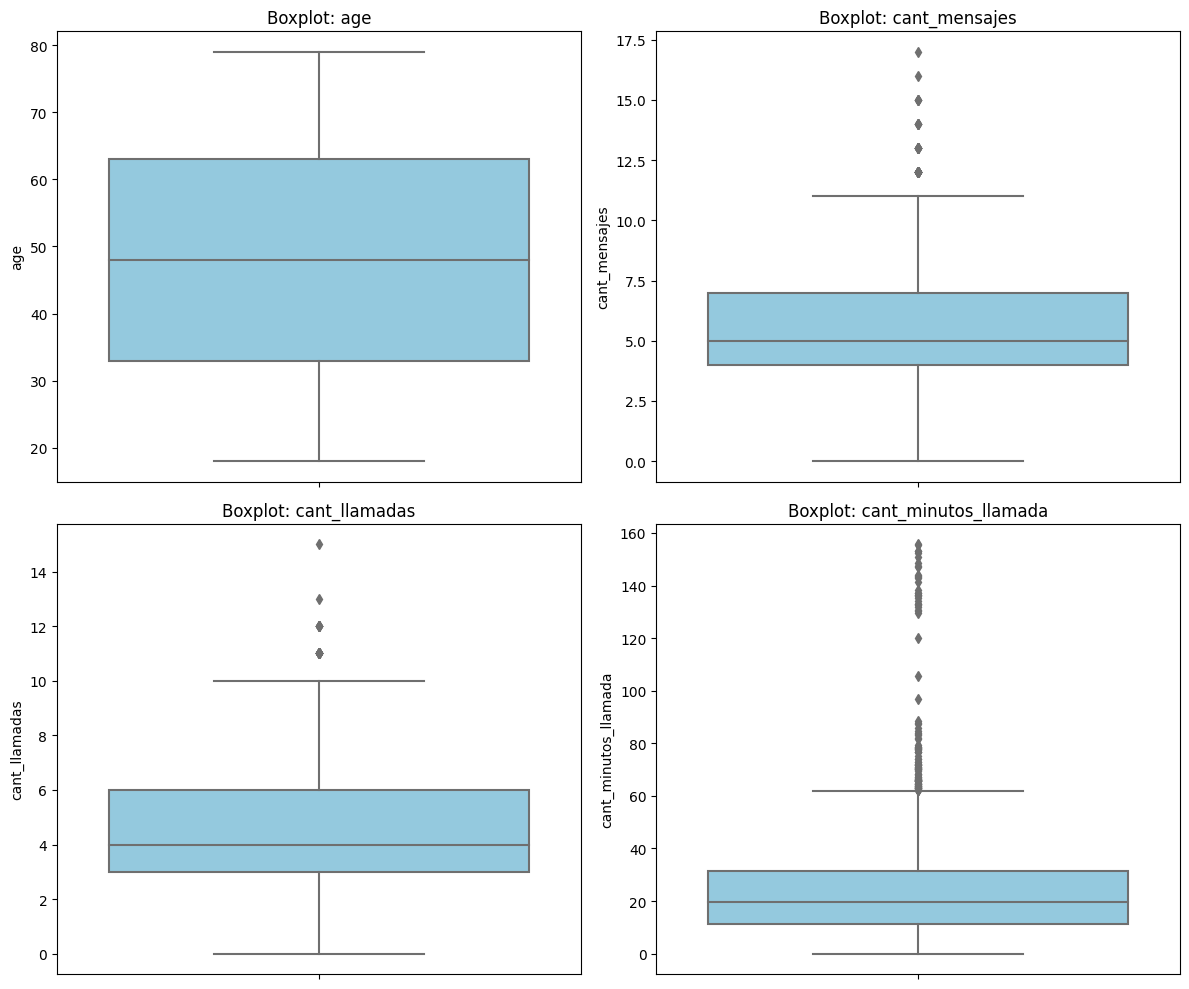

In [30]:
# Visualizando usando BoxPlot con un bucle
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

plt.figure(figsize=(12, 10))
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Generaste los 4 boxplots en un ciclo con <code>subplot</code>, en una sola figura de 2×2 con títulos dinámicos. Es una forma ordenada y compacta de presentarlos.
</div>

💡Insights: 
- Age: no se presentan outliers
- cant_mensajes: se observan outliers en la parte superior apartir del 12
- cant_llamadas: se observan outliers en la parte superior apartir del 11
- cant_minutos_llamada: se observan outliers en la parte superior apartir del 62

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Las conclusiones son correctas, pero muy breves. Indica desde qué valor aparecen los outliers (por ejemplo, minutos a partir de ~62) y borra el texto de la plantilla.
</div>

In [31]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"Límite superior para {col}: {limite_superior}")



Límite superior para cant_mensajes: 11.5
Límite superior para cant_llamadas: 10.5
Límite superior para cant_minutos_llamada: 61.8575


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Cálculo IQR correcto, y acertaste al calcular solo el límite superior.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega cuántos usuarios superan el límite para dimensionar el grupo de outliers:<br><code>print(col, (user_profile[col] &gt; limite_superior).sum(), 'usuarios por encima')</code>
</div>

In [32]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? se mantendrian porque de modificarlos los datos reales se cambiarian y dejarian de mostrar los datos reales. Este tipo de outliers puede deberse a una cantidad de usuarios pequeña que hace mayor uso de los servicios
- cant_llamadas: mantener o no outliers, porqué? tambien se mantendrian porque como explicamos en la pregunta anterior hay una pequeña porcion de usuarios que dispara las metricas sin embargo no significa que los datos sean incorrectos solo corresponden a una cierta cantidad de usuarios que tienen una mayo cantidad de llamadas
- cant_minutos_llamada: mantener o no outliers, porqué? al igual mantendriamos la cantidad de minutos

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisión correcta y bien argumentada: los outliers representan usuarios reales con mayor uso, no errores.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Refuerza el argumento con tus números: compara el límite superior con el máximo de cada variable (11.5 vs. 17 mensajes, 10.5 vs. 15 llamadas, 61.9 vs. 155.7 minutos).
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [34]:
# Crear columna grupo_uso
import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
valores = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, valores, default='Alto uso')


print(user_profile['grupo_uso'].value_counts(dropna=False))

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen uso de <code>np.select</code>! La rúbrica sugiere <code>np.where</code> anidados, pero <code>np.select</code> es igual de válido y más legible con varias condiciones. Muy bien también verificar los conteos.
</div>

In [35]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Ojo con los nulos: una comparación con <code>NaN</code> siempre da <code>False</code>. El usuario sin actividad no cumple ninguna condición y termina en el <code>default</code>: <b>"Alto uso"</b>, cuando en realidad no usó el servicio. Por eso hay 279 usuarios de alto uso, cuando en realidad son 278. Si rellenas con 0 después del merge, quedará correctamente en "Bajo uso".
</div>

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [36]:
# Crear columna grupo_edad
import numpy as np


condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
valores_edad = ['Joven', 'Adulto']


user_profile['grupo_edad'] = np.select(condiciones_edad, valores_edad, default='Adulto Mayor')


print(user_profile['grupo_edad'].value_counts(dropna=False))

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por edad correcta con <code>np.select</code>.
</div>

In [37]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

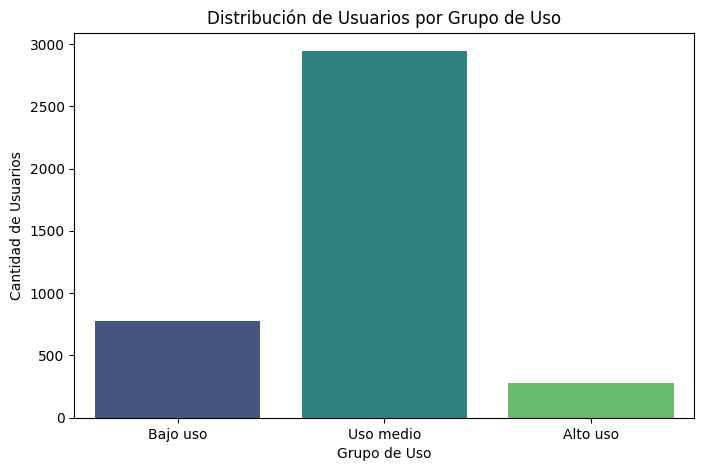

In [38]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='viridis')
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot con título, etiquetas en ambos ejes y categorías en orden lógico.
</div>

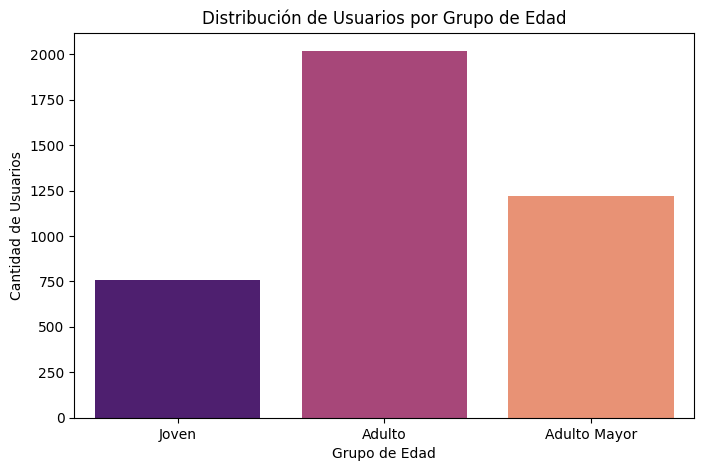

In [39]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='magma')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Gráfico de edad también ordenado y bien rotulado. Ambos countplots cumplen lo pedido.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
para city se registraron valores nulos o invalidos, para age se registraron valors invalidos como -999, para users tambien tuvimos 40 datos invalidos para el año 2026, para usage tuvimos valores de 0 para length y duration
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
se analisaron los datos para los clientes de los planes premium y basico y nos basamos en los grupos de edad joven, adulto, y adulto mayor para identificar el nivel de uso de cada grupo de edad. Pudimos descubrir que hay mas usuarios en el grupo de edad adulto con hasta 2000 usuarios y el porcentaje mas alto de usuarios hace uso medio de los servicios con una cantidad de hasta 2800 usuarios.
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
los usuarios de uso medio con una cantidad de hasta 2900 debido a que son los usuarios que mas utilidades generan para el negocio, asi como el grupo de edad adultos con hasta 2000 usuarios, debido a que el mayor porcentaje de usuarios se encuentra dentro de este grupo. Tambien se considera al grupo de usuarios de alto uso como un grupo valioso debido a ser los clientes con mayor uso de servicios con una cantidad de hasta 300
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
cantidad de llamadas, cantidad de mensajes y cantidad de minutos en llamada, esto nos podria indicar que hay una pequeña porcion de clientes que hacen mayor uso de los servicios
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
se recomendiaria analisar si los usuarios de alto uso siguen en el plan basico y si es asi ofrecer la oportunidad de unirse al plan premium. Tambien se recomienda analisar alguna estrategia de marketing para el grupo de edad joven para asi obtener mas usuarios. En el caso de los usuarios con mayor uso y que generan los outliers se recomendaria analisar la opcion de generar alguna promocion para ellos, para asi seguir generando la mayor cantidad de usuarios con uso alto.



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- valores faltantes o nulos
- fechas erroneas o pasadas
- valores atipicos o outliers

🔍 **Segmentos por Edad**
- se revisaron los datos en cuanto a edades, esto incluye jovenes para menores de 30, adulto para las personas entre los 30 y los 59 años de edad y adulto mayor para personas mayores de 60 


📊 **Segmentos por Nivel de Uso**
- se segmento a los usuarios de bajo, medio y alto uso, en cuanto a llamadas y mensajes que se realizan mensualmente


➡️ Esto sugiere que ...


💡 **Recomendaciones**

Se recomendaria hacer una campaña o promocion para los usuarios de mayor uso, se analisaria si ya cuentan con el plan premium y si no es asi se les recomendaria cambiarse al plan premium para obtener mejores beneficios. Tambien se podria analisar alguna promocion especial para personas que hacen mayor uso de mensajes que de llamadas asi como de la forma contraria para asi ofrecer un mejor precio dependiendo de las necesidades especiales de cada tipo de usuario.

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
El análisis ejecutivo es la parte donde todo tu trabajo se convierte en conclusiones para el negocio, y en esta versión todavía no responde las preguntas del paso:
<ul>
<li><b>Problemas en los datos:</b> se pide qué columnas tenían problemas y qué porcentaje o cuántas filas representaban. Tus salidas ya tienen esos números (por ejemplo, 55 edades con <code>-999</code>, 96 <code>"?"</code>, 40 fechas de 2026).</li>
<li><b>Segmentos:</b> además de definirlos, indica su tamaño y cómo se comportan. Ya calculaste los conteos en el paso 6.</li>
<li><b>Segmentos más valiosos:</b> ¿cuáles son y por qué?</li>
<li><b>Outliers:</b> ¿qué patrones de uso extremo encontraste y qué implican para el negocio?</li>
<li><b>"Esto sugiere que..."</b> quedó vacío.</li>
</ul>
Ten en cuenta también que los datos son el <b>total del periodo</b> por usuario, no valores mensuales. Tus recomendaciones van por buen camino (ofertas según el tipo de uso); conéctalas con las cifras para que sean más convincentes.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Escribe el link en esta celda Markdown, reemplazando el texto de la plantilla <code>`LINK a tu repo aquí`</code>.
</div>

In [ ]:
https://github.com/macriquego-art/analysis-everpeak/blob/main/README.md

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Dos detalles con el link:
<ul>
<li>Está en una celda de <b>código</b>: al ejecutar todo el notebook, esta celda produce un <code>SyntaxError</code>. Muévelo a la celda Markdown de arriba y elimina esta celda.</li>
<li>El repositorio se llama <code>analysis-everpeak</code> y el link apunta al README. Verifica que sea el de este proyecto (ConnectaTel), comparte el link al repositorio y asegúrate de que incluya el notebook y un <code>README.md</code> con objetivo, datasets, etapas del análisis y cómo ejecutarlo.</li>
</ul>
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>🟡 no identificados en el diagnóstico</td></tr><tr><td></td><td>Fechas (errors='coerce', .dt.year)</td><td>✅</td></tr><tr><td></td><td>Interpretaciones del paso 2.2</td><td>❌ cuatro celdas sin contestar</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>✅</td></tr><tr><td></td><td>"?" → pd.NA</td><td>✅</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>✅</td></tr><tr><td></td><td>Evaluación MAR y decisión</td><td>✅</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅ (sugerencia: fillna(0))</td></tr><tr><td></td><td>Revisión estadística</td><td>🟡 incluye user_id, sin interpretación</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas con hue</td><td>✅</td></tr><tr><td></td><td>Interpretación</td><td>🟡 comparaciones entre planes sin respaldo</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅ (ojo con NaN → Alto uso)</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Segmentos y comportamiento</td><td>❌ sin cifras ni análisis de comportamiento</td></tr><tr><td></td><td>Segmentos valiosos</td><td>❌ no identificados</td></tr><tr><td></td><td>Recomendaciones</td><td>🟡 generales</td></tr><tr><td>8. Publicación</td><td>Link al repositorio</td><td>🟡 en celda de código; verificar repo</td></tr></table><br>Criterios en ❌ (pasos 2.2 y 7) → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Tu proyecto tiene una base técnica muy sólida. Para la siguiente iteración, los puntos bloqueantes ❌ son:
<ol><li><b>Interpretaciones del paso 2.2:</b> contestar las cuatro celdas que quedaron con el texto de la plantilla, describiendo lo que muestran tus salidas (incluidos los sentinels <code>-999</code> y <code>"?"</code>).</li>
<li><b>Análisis ejecutivo (paso 7):</b> responder cada pregunta con las cifras que ya calculaste (problemas de datos, tamaño y comportamiento de los segmentos, segmentos más valiosos, outliers) y completar \"Esto sugiere que...\".</li></ol>
En la siguiente iteración revisaré únicamente estos puntos, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente corregir el diagnóstico de fechas y mover el link a la celda Markdown.<br><br>
¡Ánimo, ya casi está! 💪
</div>